<a href="https://colab.research.google.com/github/Mariana-Lealdini/MVP_VINHOS/blob/main/api/MachineLearning/notebooks/MVP_Vinhos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP - Engenharia de Sistemas de Software Inteligentes
## Classificação da Qualidade de Vinhos a partir de Medidas Químicas

**Objetivo do notebook:** Construir, avaliar e exportar um modelo de *machine learning* que, a partir das medidas químicas de um vinho, preveja se a qualidade dele é baixa, média ou alta. O modelo exportado será usado depois em uma aplicação *full stack*.

## 1. Contexto do Problema

Avaliar a qualidade de um vinho normalmente depende de degustadores especialistas, o que é caro e subjetivo. Já as medidas químicas, como acidez, açúcar e teor alcoólico, são feitas em laboratório de forma rotineira. A questão deste trabalho é se a avaliação dos especialistas pode ser prevista usando apenas as medidas químicas.

**Dataset:** *Wine Quality*, do UCI Machine Learning Repository, com amostras de vinhos tintos e brancos da denominação de origem Vinho Verde, região do Minho, no norte de Portugal.
Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). *Modeling wine preferences by data mining from physicochemical properties*. Decision Support Systems, 47(4), 547-553. Licença CC BY 4.0. DOI do dataset: 10.24432/C56S3T.

**Entradas:** 11 medidas químicas contínuas e o tipo do vinho, tinto ou branco. O tipo é criado ao unir os dois arquivos do dataset.

**Saída:** A nota original vai de 0 a 10 e corresponde à mediana de pelo menos 3 avaliações de especialistas. Neste trabalho, a nota foi agrupada em três classes:

| Classe | Nota original |
|---|---|
| baixa | 5 ou menos |
| média | 6 |
| alta | 7 ou mais |

Trata-se, portanto, de um problema de classificação supervisionada com 3 classes, que seguem uma ordem natural: baixa, média e alta.

## 2. Configuração do Ambiente

Nesta etapa são importadas as bibliotecas usadas no notebook. Também é exibida a versão do *scikit-learn*, porque o modelo será salvo em arquivo e carregado depois pela aplicação, e um arquivo salvo com uma versão da biblioteca pode não funcionar em outra. A mesma versão será fixada no `requirements.txt` da aplicação.

In [1]:
# Imports necessários
import hashlib  # cálculo do hash do arquivo do modelo
import pickle   # salvar e carregar o modelo em arquivo
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

# Separação dos dados e validação cruzada
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV,
)

# Transformações dos dados e pipelines
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline

# Algoritmos de classificação
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Métricas de avaliação
from sklearn.metrics import (
    make_scorer, f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay,
)

print("Versão do scikit-learn:", sklearn.__version__)

Versão do scikit-learn: 1.6.1


## 3. Carga dos Dados

Os dois arquivos CSV originais do UCI estão no repositório do projeto no GitHub e são lidos diretamente pela URL "raw", que entrega apenas o conteúdo do arquivo. Assim, o notebook roda no Google Colab sem nenhuma configuração.

Atenção:
- Os arquivos usam ponto e vírgula como separador, e não vírgula. Por isso a leitura é feita com `sep=";"`.
- Vinhos tintos e brancos estão em arquivos separados. Antes de juntá-los, é acrescentada a coluna `tipo`, pois sem ela não seria possível saber de qual arquivo cada linha veio.
- Os nomes das colunas originais estão em inglês e têm espaços. Elas são renomeadas para português, sem espaços, o que facilita o uso na aplicação, onde os nomes viram campos do formulário e do JSON.

In [2]:
# Endereço dos arquivos (versão "raw" do GitHub)
URL_BASE = ("https://raw.githubusercontent.com/Mariana-Lealdini/MVP_VINHOS/"
            "main/api/MachineLearning/data/")
URL_TINTO = URL_BASE + "winequality-red.csv"
URL_BRANCO = URL_BASE + "winequality-white.csv"

# Nomes das colunas em português, sem espaços
COLUNAS = {
    "fixed acidity": "acidez_fixa",
    "volatile acidity": "acidez_volatil",
    "citric acid": "acido_citrico",
    "residual sugar": "acucar_residual",
    "chlorides": "cloretos",
    "free sulfur dioxide": "dioxido_enxofre_livre",
    "total sulfur dioxide": "dioxido_enxofre_total",
    "density": "densidade",
    "pH": "ph",
    "sulphates": "sulfatos",
    "alcohol": "alcool",
    "quality": "qualidade",
}


def carregar_vinhos(url: str, tipo: str) -> pd.DataFrame:
    """Lê um CSV de vinhos, renomeia as colunas e acrescenta a coluna 'tipo'."""
    vinhos = pd.read_csv(url, sep=";")
    vinhos = vinhos.rename(columns=COLUNAS)
    vinhos["tipo"] = tipo
    return vinhos


tintos = carregar_vinhos(URL_TINTO, "tinto")
brancos = carregar_vinhos(URL_BRANCO, "branco")

# Junta os dois conjuntos em um único dataset
dataset = pd.concat([tintos, brancos], ignore_index=True)

print(f"Tintos: {tintos.shape[0]} linhas | Brancos: {brancos.shape[0]} linhas")
print(f"Dataset unido: {dataset.shape[0]} linhas e {dataset.shape[1]} colunas")

Tintos: 1599 linhas | Brancos: 4898 linhas
Dataset unido: 6497 linhas e 13 colunas


## 4. Primeira Inspeção dos Dados

Antes de modelar, é preciso conhecer os dados. Nesta etapa são observadas as primeiras linhas, os tipos de cada coluna, a existência de valores ausentes e as estatísticas básicas.

O que observar nos resultados:
- **Tipos:** As 11 medidas devem ser numéricas e `tipo` deve ser texto.
- **Valores ausentes:** Se existissem, seria preciso tratá-los antes do treino.
- **Escalas diferentes entre colunas:** `dioxido_enxofre_total` chega a centenas, enquanto `densidade` fica perto de 1. Isso será importante mais adiante, pois algoritmos como KNN e SVM são sensíveis à escala dos atributos.

In [3]:
# Primeiras linhas
dataset.head()

,acidez_fixa,acidez_volatil,acido_citrico,acucar_residual,cloretos,dioxido_enxofre_livre,dioxido_enxofre_total,densidade,ph,sulfatos,alcool,qualidade,tipo
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,tinto
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,tinto
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,tinto
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,tinto


In [4]:
# Tipos das colunas e valores ausentes
print(dataset.dtypes)
print()
print("Total de valores ausentes:", dataset.isna().sum().sum())

acidez_fixa              float64
acidez_volatil           float64
acido_citrico            float64
acucar_residual          float64
cloretos                 float64
dioxido_enxofre_livre    float64
dioxido_enxofre_total    float64
densidade                float64
ph                       float64
sulfatos                 float64
alcool                   float64
qualidade                  int64
tipo                      object
dtype: object

Total de valores ausentes: 0


In [5]:
# Estatísticas básicas das medidas químicas
dataset.describe().round(3)

,acidez_fixa,acidez_volatil,acido_citrico,acucar_residual,cloretos,dioxido_enxofre_livre,dioxido_enxofre_total,densidade,ph,sulfatos,alcool,qualidade
count,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000
mean,7.215,0.340,0.319,5.443,0.056,30.525,115.745,0.995,3.219,0.531,10.492,5.818
std,1.296,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000
75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000


## 5. Definição das Classes

A nota original (`qualidade`) é um número inteiro. Como o objetivo é classificar os vinhos em baixa, média ou alta, a coluna `classe` é criada a partir dela, conforme a tabela da seção 1.

Atenção:
- **A coluna `qualidade` não pode ser usada como atributo de entrada.** Ela é a própria informação que se deseja prever, e usá-la como entrada seria entregar a resposta ao modelo, o que caracteriza vazamento de dados. Apenas as 11 medidas químicas e o tipo serão usados como entradas.
- **As classes são desbalanceadas.** Por isso é medida a proporção de cada uma e calculada uma linha de base, que é a acurácia de um modelo que sempre responde a classe mais comum. Qualquer modelo útil precisa superar esse valor.

In [6]:
ORDEM_CLASSES = ["baixa", "media", "alta"]


def classificar_qualidade(nota: int) -> str:
    """Agrupa a nota original (0 a 10) em baixa, média ou alta."""
    if nota <= 5:
        return "baixa"
    if nota == 6:
        return "media"
    return "alta"


dataset["classe"] = dataset["qualidade"].apply(classificar_qualidade)

# Proporção de cada classe
proporcoes = dataset["classe"].value_counts(normalize=True)[ORDEM_CLASSES]
for classe, proporcao in proporcoes.items():
    print(f"{classe}: {proporcao:.1%}")

# Linha de base: sempre responder a classe mais comum
print(f"\nLinha de base (classe mais comum): {proporcoes.max():.1%} de acurácia")

baixa: 36.7%
media: 43.7%
alta: 19.7%

Linha de base (classe mais comum): 43.7% de acurácia


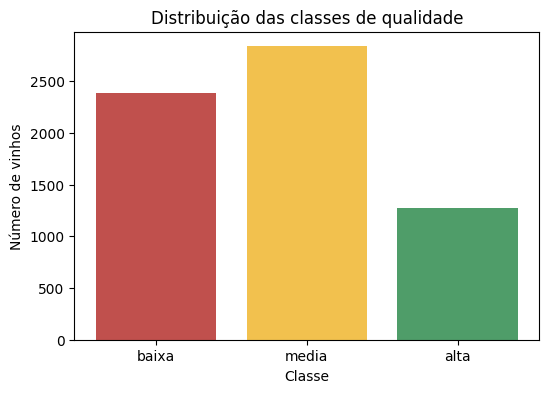

In [7]:
# Visualização da distribuição das classes
contagem = dataset["classe"].value_counts()[ORDEM_CLASSES]
plt.figure(figsize=(6, 4))
plt.bar(contagem.index, contagem.values, color=["#c0504d", "#f2c14e", "#4f9d69"])
plt.title("Distribuição das classes de qualidade")
plt.xlabel("Classe")
plt.ylabel("Número de vinhos")
plt.show()

## 6. Limpeza: Linhas Duplicadas

É preciso verificar se existem vinhos repetidos no dataset por causa do vazamento de dados. Se a mesma linha aparecer no treino e no teste, o modelo acerta o teste porque já viu aquele vinho, e a acurácia fica inflada. O teste existe para simular dados novos, e linhas repetidas comprometem essa simulação.

Também é verificado se há linhas com medidas idênticas, mas notas diferentes. Se houvesse, remover as duplicatas poderia descartar informação conflitante. A remoção é feita antes da separação em treino e teste, pois, se fosse feita depois, uma cópia poderia ficar no treino e a outra no teste.

In [8]:
colunas_entrada = [c for c in dataset.columns if c not in ("qualidade", "classe")]

n_duplicadas = dataset.duplicated().sum()
print(f"Linhas duplicadas: {n_duplicadas} ({n_duplicadas / len(dataset):.1%})")

# Medidas idênticas com notas diferentes?
notas_por_vinho = dataset.groupby(colunas_entrada)["qualidade"].nunique()
print("Vinhos idênticos com notas diferentes:", (notas_por_vinho > 1).sum())

Linhas duplicadas: 1177 (18.1%)
Vinhos idênticos com notas diferentes: 0


In [9]:
# Remove as duplicatas (mantém a primeira ocorrência)
dataset = dataset.drop_duplicates().reset_index(drop=True)

print(f"Dataset após a limpeza: {dataset.shape[0]} linhas")
for tipo, quantidade in dataset["tipo"].value_counts().items():
    print(f"{tipo}: {quantidade} vinhos")
print()
for classe, proporcao in dataset["classe"].value_counts(normalize=True)[ORDEM_CLASSES].items():
    print(f"{classe}: {proporcao:.1%}")

Dataset após a limpeza: 5320 linhas
branco: 3961 vinhos
tinto: 1359 vinhos

baixa: 37.4%
media: 43.7%
alta: 19.0%


**Resultado da limpeza:** As linhas repetidas foram removidas, e a proporção entre as classes praticamente não mudou. O dataset limpo é a base para a próxima etapa, a separação em conjuntos de treino e teste.

## 7. Preparação das Entradas: Tipo do Vinho em Formato Numérico

Os algoritmos do *scikit-learn* só trabalham com números, mas a coluna `tipo` é texto. Por isso foi criada a coluna `tipo_branco`, que vale 1 para vinho branco e 0 para tinto. Ela carrega a mesma informação, apenas em forma numérica.

Essa troca pode ser feita antes da separação em treino e teste sem risco de vazamento de dados, porque é uma regra fixa e não aprende nada com os dados. A normalização e a padronização são diferentes: Elas calculam valores a partir dos dados, como mínimo, máximo, média e desvio padrão, e por isso precisam ficar dentro do *pipeline*.

Nesta etapa também é definida a lista final de atributos de entrada, com as 11 medidas químicas e o `tipo_branco`. As colunas `qualidade` e `classe` ficam de fora, pois representam a resposta a ser prevista.

In [10]:
# Converte o tipo do vinho em número: branco = 1, tinto = 0
dataset["tipo_branco"] = (dataset["tipo"] == "branco").astype(int)

# Atributos de entrada (X): as 11 medidas químicas e o tipo em forma numérica
ATRIBUTOS = [
    "acidez_fixa", "acidez_volatil", "acido_citrico", "acucar_residual",
    "cloretos", "dioxido_enxofre_livre", "dioxido_enxofre_total",
    "densidade", "ph", "sulfatos", "alcool", "tipo_branco",
]

# Conferência: a contagem de brancos e tintos deve ser a mesma da seção 6
print(dataset[["tipo", "tipo_branco"]].value_counts())

tipo    tipo_branco
branco  1              3961
tinto   0              1359
Name: count, dtype: int64


## 8. Separação em Treino e Teste (*holdout*)

Para saber se o modelo funciona em vinhos que ele nunca viu, os dados são separados em dois conjuntos:

- **Treino (80%):** Usado para escolher e treinar os modelos. A comparação entre algoritmos, a validação cruzada e o ajuste de hiperparâmetros acontecem apenas neste conjunto.
- **Teste (20%):** Guardado até o fim e usado uma única vez, para avaliar o modelo escolhido como se fossem dados novos.

Decisões desta etapa:

- **Proporção 80/20:** A mesma do exemplo prático do curso. Com 5.320 vinhos, o teste fica com 1.064 vinhos, o suficiente para uma avaliação confiável.
- **Estratificação com `stratify=y`:** Garante que treino e teste tenham a mesma proporção de baixa, média e alta. Isso é necessário porque a classe alta é rara, com 19% dos vinhos, e sem estratificação um dos conjuntos poderia ficar com poucos exemplos dela.
- **Semente aleatória com `random_state=7`:** A separação é sorteada, e a semente fixa o sorteio. Assim, uma nova execução do notebook gera a mesma separação e os mesmos resultados.

Comentário: As duplicatas já foram removidas na seção 6, então nenhum vinho aparece ao mesmo tempo no treino e no teste.

In [11]:
TAMANHO_TESTE = 0.20  # 20% dos dados vão para o teste
SEMENTE = 7          # semente aleatória fixa, para resultados reproduzíveis

X = dataset[ATRIBUTOS]
y = dataset["classe"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=TAMANHO_TESTE,
    random_state=SEMENTE,
    stratify=y,  # mantém a proporção das classes nos dois conjuntos
)

print(f"Treino: {X_treino.shape[0]} vinhos | Teste: {X_teste.shape[0]} vinhos")
print(f"Atributos de entrada: {X_treino.shape[1]}")

Treino: 4256 vinhos | Teste: 1064 vinhos
Atributos de entrada: 12


In [12]:
# Conferência da estratificação: proporção das classes em cada conjunto
comparacao = pd.DataFrame({
    "dataset completo": y.value_counts(normalize=True),
    "treino": y_treino.value_counts(normalize=True),
    "teste": y_teste.value_counts(normalize=True),
}).loc[ORDEM_CLASSES]

(comparacao * 100).round(1)

,dataset completo,treino,teste
classe,,,
baixa,37.4,37.4,37.3
media,43.7,43.7,43.7
alta,19.0,19.0,19.0


**Resultado da separação:** As proporções de baixa, média e alta são praticamente iguais no dataset completo, no treino e no teste, o que confirma que a estratificação funcionou. A partir daqui, o conjunto de teste fica guardado e as próximas etapas usam apenas o conjunto de treino.

## 9. Critérios de Avaliação dos Modelos

Antes do treino, são definidos a forma de medir se um modelo é bom e a forma de comparar os modelos de maneira justa.

### Métricas

- **Acurácia:** Percentual de vinhos classificados corretamente. É a métrica mais intuitiva, mas engana quando as classes são desbalanceadas. Um modelo que nunca acerta a classe alta, com 19% dos vinhos, ainda pode ter uma acurácia razoável.
- **F1 macro:** Para cada classe, o F1 combina a precisão e o recall. A precisão indica, dos vinhos que o modelo classificou como alta, quantos eram de fato alta. O recall indica, dos vinhos que eram alta, quantos o modelo encontrou. O F1 macro é a média simples do F1 das três classes e dá o mesmo peso a cada uma, de modo que errar muito a classe rara reduz a nota.

Por isso o F1 macro é a métrica principal para escolher o modelo, e a acurácia é a métrica complementar, por ser mais fácil de interpretar.

Se um modelo nunca prevê uma das classes, a precisão dessa classe fica indefinida, pois há uma divisão por zero. O parâmetro `zero_division=0` faz o *scikit-learn* considerar essa precisão como zero, que é a avaliação justa para um modelo que ignora uma classe.

### Validação Cruzada

Avaliar cada modelo em uma única divisão do treino daria um resultado dependente da sorte da divisão. Na validação cruzada com 10 partições, o conjunto de treino é dividido em 10 partes. O modelo é treinado em 9 e avaliado na parte restante, e o processo se repete 10 vezes, até que cada parte tenha sido usada uma vez na avaliação. O resultado é uma média, que representa o desempenho esperado, e um desvio padrão, que mostra o quanto o desempenho varia.

É usada a versão estratificada (`StratifiedKFold`), que mantém a proporção das classes em cada parte, pelo mesmo motivo da estratificação no *holdout*. A semente é a mesma da seção 8, para que as partes sejam sempre as mesmas.

Comentário: A validação cruzada usa somente o conjunto de treino. O conjunto de teste continua guardado.

In [13]:
NUM_PARTICOES = 10

# Validação cruzada estratificada: 10 partes com a mesma proporção de classes
kfold = StratifiedKFold(n_splits=NUM_PARTICOES, shuffle=True, random_state=SEMENTE)

# Métricas calculadas em cada rodada da validação cruzada
METRICAS = {
    "acuracia": "accuracy",
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}

## 10. Comparação dos Algoritmos com *Pipelines*

Nesta etapa são comparados os quatro algoritmos pedidos, KNN, Árvore de Classificação, Naive Bayes e SVM, cada um com os hiperparâmetros padrão. O ajuste dos hiperparâmetros é feito na seção 11.

### Três Versões dos Dados

Cada algoritmo é testado com os dados em três versões:

- **Original (`orig`):** Sem transformação.
- **Padronizada (`padr`, `StandardScaler`):** Cada atributo passa a ter média 0 e desvio padrão 1.
- **Normalizada (`norm`, `MinMaxScaler`):** Cada atributo passa a variar entre 0 e 1.

Conforme a seção 4, os atributos têm escalas muito diferentes. O KNN, que mede distâncias, e o SVM, que calcula produtos entre os atributos, são sensíveis a isso. Já a Árvore e o Naive Bayes tendem a não ser afetados, e a comparação permite confirmar esse comportamento.

### Uso de *Pipelines*

A padronização e a normalização aprendem valores com os dados. Se fossem calculadas com todos os dados de uma vez, informação das partes de avaliação vazaria para o treino. O `Pipeline` encadeia a transformação e o algoritmo, e a validação cruzada passa a ajustar a transformação apenas com as 9 partes de treino de cada rodada, aplicando-a depois na parte de avaliação. Dessa forma, o vazamento de dados é evitado.

### Modelo de Referência

Também foi incluído um modelo de referência (`DummyClassifier`), que sempre responde a classe mais comum, "media". Ele corresponde à linha de base da seção 5 e mostra o mínimo que qualquer modelo útil precisa superar, agora também em F1 macro.

Comentário: A Árvore recebe `random_state=SEMENTE` porque, em caso de empate na escolha das divisões, ela faz um sorteio. A semente torna o resultado reproduzível.

In [14]:
# Algoritmos com os hiperparâmetros padrão do scikit-learn
ALGORITMOS = {
    "KNN": KNeighborsClassifier(),
    "Arvore": DecisionTreeClassifier(random_state=SEMENTE),
    "NB": GaussianNB(),
    "SVM": SVC(),
}

# Versões dos dados: original (sem transformação), padronizada e normalizada
TRANSFORMACOES = {
    "orig": None,
    "padr": StandardScaler(),
    "norm": MinMaxScaler(),
}


def montar_pipeline(transformacao, algoritmo) -> Pipeline:
    """Monta um pipeline com a transformação (se houver) seguida do algoritmo."""
    passos = []
    if transformacao is not None:
        passos.append(("transformacao", transformacao))
    passos.append(("modelo", algoritmo))
    return Pipeline(passos)


# Modelo de referência + as 12 combinações (4 algoritmos x 3 versões dos dados)
pipelines = {
    "Referencia": montar_pipeline(None, DummyClassifier(strategy="most_frequent")),
}
for nome_algoritmo, algoritmo in ALGORITMOS.items():
    for nome_transformacao, transformacao in TRANSFORMACOES.items():
        nome = f"{nome_algoritmo}-{nome_transformacao}"
        pipelines[nome] = montar_pipeline(transformacao, algoritmo)

print(f"{len(pipelines)} pipelines montados:", ", ".join(pipelines))

13 pipelines montados: Referencia, KNN-orig, KNN-padr, KNN-norm, Arvore-orig, Arvore-padr, Arvore-norm, NB-orig, NB-padr, NB-norm, SVM-orig, SVM-padr, SVM-norm


In [15]:
# Avalia cada pipeline com validação cruzada (somente no conjunto de treino)
f1_por_particao = {}  # F1 macro de cada uma das 10 rodadas, para o gráfico
resumo = []           # média e desvio padrão de cada pipeline, para a tabela

for nome, pipeline in pipelines.items():
    resultado = cross_validate(pipeline, X_treino, y_treino, cv=kfold, scoring=METRICAS)
    f1_por_particao[nome] = resultado["test_f1_macro"]
    resumo.append({
        "pipeline": nome,
        "f1_macro_media": resultado["test_f1_macro"].mean(),
        "f1_macro_desvio": resultado["test_f1_macro"].std(),
        "acuracia_media": resultado["test_acuracia"].mean(),
        "acuracia_desvio": resultado["test_acuracia"].std(),
    })

# Tabela ordenada do melhor para o pior F1 macro
tabela_comparacao = (
    pd.DataFrame(resumo)
    .set_index("pipeline")
    .sort_values("f1_macro_media", ascending=False)
)
tabela_comparacao.round(3)

,f1_macro_media,f1_macro_desvio,acuracia_media,acuracia_desvio
pipeline,,,,
SVM-padr,0.577,0.028,0.613,0.027
KNN-padr,0.553,0.024,0.561,0.025
KNN-norm,0.547,0.012,0.556,0.012
SVM-norm,0.543,0.026,0.595,0.024
Arvore-padr,0.505,0.010,0.521,0.008
Arvore-norm,0.504,0.011,0.521,0.009
Arvore-orig,0.502,0.012,0.519,0.009
NB-orig,0.491,0.013,0.490,0.014
NB-padr,0.490,0.011,0.490,0.012


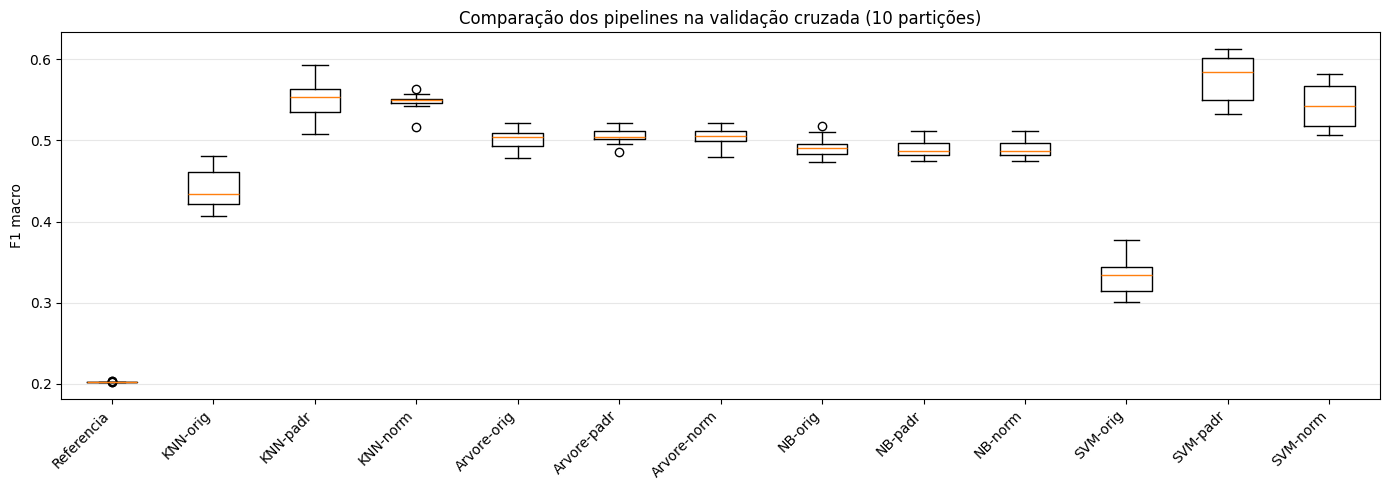

In [16]:
# Boxplot: distribuição do F1 macro nas 10 rodadas de cada pipeline
fig, ax = plt.subplots(figsize=(14, 5))
ax.boxplot(list(f1_por_particao.values()))
ax.set_xticks(range(1, len(f1_por_particao) + 1))
ax.set_xticklabels(f1_por_particao.keys(), rotation=45, ha="right")
ax.set_title("Comparação dos pipelines na validação cruzada (10 partições)")
ax.set_ylabel("F1 macro")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Análise da comparação.**

- Todos os algoritmos superam a referência, que acerta 43,7% dos vinhos, mas tem F1 macro de apenas 0,20 porque ignora as classes baixa e alta.
- O SVM com dados padronizados teve o melhor resultado, com F1 macro de 0,577 e acurácia de 61%, seguido do KNN padronizado e normalizado.
- A escala dos dados faz muita diferença para KNN e SVM. Sem transformação, o F1 macro do SVM cai para 0,33, pois com os atributos em escalas tão diferentes ele praticamente deixa de reconhecer as classes menos comuns. O KNN perde mais de 0,10 de F1 macro sem transformação.
- Árvore e Naive Bayes quase não mudam entre as três versões, como esperado. A Árvore compara cada atributo com um limite, e a escala não altera essas comparações. O Naive Bayes analisa a distribuição de cada atributo separadamente.
- Os desvios padrão são pequenos, entre 0,01 e 0,03, o que indica resultados estáveis entre as rodadas. As diferenças entre os melhores e os piores pipelines são bem maiores que essa variação.

O desempenho geral é moderado, já que mesmo o melhor modelo erra cerca de 4 em cada 10 vinhos. Isso é coerente com o problema, pois a nota vem de avaliações humanas, que são subjetivas, e vinhos com medidas químicas parecidas podem receber notas diferentes. Na próxima seção, os hiperparâmetros são ajustados para tentar melhorar esses resultados.

## 11. Otimização de Hiperparâmetros

Na seção 10, cada algoritmo usou as configurações padrão do *scikit-learn*. Os algoritmos, porém, têm hiperparâmetros, que são escolhas feitas antes do treino e que mudam o comportamento do modelo, como a quantidade de vizinhos consultados pelo KNN. Eles são diferentes dos parâmetros, que o modelo aprende durante o treino.

Para encontrar boas combinações, é usado o `GridSearchCV`, que faz uma busca em grade. Para cada hiperparâmetro é informada uma lista de valores, e a busca testa todas as combinações, avaliando cada uma com a mesma validação cruzada de 10 partições da seção 9, somente no conjunto de treino. A melhor combinação é escolhida pelo F1 macro, a métrica principal.

### Hiperparâmetros Testados

| Algoritmo | Hiperparâmetro | O que controla |
|---|---|---|
| KNN | `n_neighbors` (1 a 31, ímpares) | Quantidade de vizinhos consultados. Com poucos vizinhos, o modelo fica sensível a ruído. Com muitos, fica genérico demais. Números ímpares reduzem empates. |
| KNN | `metric` | Forma de medir a distância: Euclidiana, em linha reta, ou manhattan, pela soma das diferenças de cada atributo. |
| KNN | `weights` | Se todos os vizinhos votam com o mesmo peso (`uniform`) ou se os mais próximos têm voto mais forte (`distance`). |
| Árvore | `criterion` | Medida usada para escolher as divisões: Gini ou entropia. A entropia é a medida usada pelo C4.5, visto na disciplina. |
| Árvore | `max_depth` | Profundidade máxima. Limitar a profundidade é uma forma de poda, que combate o *overfitting*. |
| Árvore | `min_samples_leaf` | Mínimo de vinhos em cada folha. Também evita regras específicas demais. |
| Naive Bayes | `var_smoothing` | Pequeno valor somado às variâncias para dar estabilidade aos cálculos. É o principal hiperparâmetro do `GaussianNB`. |
| SVM | `kernel` | Forma da fronteira de decisão: Linear ou radial (`rbf`), que permite fronteiras curvas. |
| SVM | `C` | Rigidez da margem. Valores pequenos toleram mais erros no treino e deixam a margem mais flexível. Valores grandes tentam acertar todos os exemplos. |
| SVM | `gamma` | Alcance da influência de cada vinho de treino no kernel `rbf`. Valores altos geram fronteiras muito recortadas. |

### Transformação dos Dados na Busca

O passo de transformação do *pipeline* também entra na grade, então a busca escolhe entre padronizar e normalizar. Os resultados da seção 10 foram usados para evitar combinações que já se mostraram ruins:

- **KNN e SVM:** Testam padronização e normalização. Sem transformação, os dois foram muito piores, e o SVM com dados originais também é muito lento para treinar.
- **Árvore e Naive Bayes:** Usam os dados originais, indicados por `"passthrough"`, já que a escala praticamente não alterou os resultados desses algoritmos.

O parâmetro `n_jobs=-1` faz a busca usar todos os processadores disponíveis. Mesmo assim, esta seção leva alguns minutos para rodar, principalmente por causa do SVM.

In [17]:
TRANSFORMACOES_ESCALA = [StandardScaler(), MinMaxScaler()]

# Grade de hiperparâmetros de cada algoritmo.
# O prefixo "modelo__" indica que o hiperparâmetro pertence ao passo "modelo" do pipeline.
GRADES = {
    "KNN": {
        "transformacao": TRANSFORMACOES_ESCALA,
        "modelo__n_neighbors": list(range(1, 32, 2)),
        "modelo__metric": ["euclidean", "manhattan"],
        "modelo__weights": ["uniform", "distance"],
    },
    "Arvore": {
        "transformacao": ["passthrough"],
        "modelo__criterion": ["gini", "entropy"],
        "modelo__max_depth": [None, 3, 5, 7, 10, 15, 20],
        "modelo__min_samples_leaf": [1, 2, 5, 10, 20],
    },
    "NB": {
        "transformacao": ["passthrough"],
        "modelo__var_smoothing": np.logspace(-9, -1, 9),  # 1e-9, 1e-8, ..., 1e-1
    },
    # Duas grades para o SVM, porque o gamma só faz sentido no kernel rbf
    "SVM": [
        {
            "transformacao": TRANSFORMACOES_ESCALA,
            "modelo__kernel": ["rbf"],
            "modelo__C": [0.1, 1, 10, 100],
            "modelo__gamma": ["scale", 0.01, 0.1, 1],
        },
        {
            "transformacao": TRANSFORMACOES_ESCALA,
            "modelo__kernel": ["linear"],
            "modelo__C": [0.1, 1, 10],
        },
    ],
}

In [18]:
# Executa a busca em grade para cada algoritmo (pode levar alguns minutos)
buscas = {}

for nome, algoritmo in ALGORITMOS.items():
    # O passo "transformacao" começa vazio e é preenchido pela própria busca
    pipeline = Pipeline([("transformacao", "passthrough"), ("modelo", algoritmo)])
    busca = GridSearchCV(
        pipeline,
        GRADES[nome],
        cv=kfold,
        scoring=METRICAS,
        refit="f1_macro",  # critério de escolha da melhor combinação
        n_jobs=-1,
    )
    busca.fit(X_treino, y_treino)
    buscas[nome] = busca
    print(f"{nome}: busca concluída ({len(busca.cv_results_['params'])} combinações testadas)")

KNN: busca concluída (128 combinações testadas)
Arvore: busca concluída (70 combinações testadas)
NB: busca concluída (9 combinações testadas)
SVM: busca concluída (38 combinações testadas)


In [19]:
# Resumo: melhor combinação de cada algoritmo, comparada com a configuração padrão
resumo_otimizacao = []

for nome, busca in buscas.items():
    melhor = busca.best_index_
    # Melhor resultado do algoritmo na seção 10 (configuração padrão)
    f1_padrao = tabela_comparacao.loc[
        tabela_comparacao.index.str.startswith(f"{nome}-"), "f1_macro_media"
    ].max()
    resumo_otimizacao.append({
        "algoritmo": nome,
        "f1_macro_padrao": f1_padrao,
        "f1_macro_otimizado": busca.cv_results_["mean_test_f1_macro"][melhor],
        "f1_macro_desvio": busca.cv_results_["std_test_f1_macro"][melhor],
        "acuracia_otimizada": busca.cv_results_["mean_test_acuracia"][melhor],
        "melhores_hiperparametros": busca.best_params_,
    })

tabela_otimizacao = (
    pd.DataFrame(resumo_otimizacao)
    .set_index("algoritmo")
    .sort_values("f1_macro_otimizado", ascending=False)
)

# Exibe os hiperparâmetros por extenso, sem cortar o texto
with pd.option_context("display.max_colwidth", None):
    display(tabela_otimizacao.round(3))

,f1_macro_padrao,f1_macro_otimizado,f1_macro_desvio,acuracia_otimizada,melhores_hiperparametros
algoritmo,,,,,
KNN,0.553,0.595,0.026,0.609,"{'modelo__metric': 'manhattan', 'modelo__n_neighbors': 21, 'modelo__weights': 'distance', 'transformacao': StandardScaler()}"
SVM,0.577,0.582,0.031,0.605,"{'modelo__C': 10, 'modelo__gamma': 0.1, 'modelo__kernel': 'rbf', 'transformacao': StandardScaler()}"
Arvore,0.505,0.549,0.019,0.575,"{'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 2, 'transformacao': 'passthrough'}"
NB,0.491,0.528,0.027,0.536,"{'modelo__var_smoothing': 1e-05, 'transformacao': 'passthrough'}"


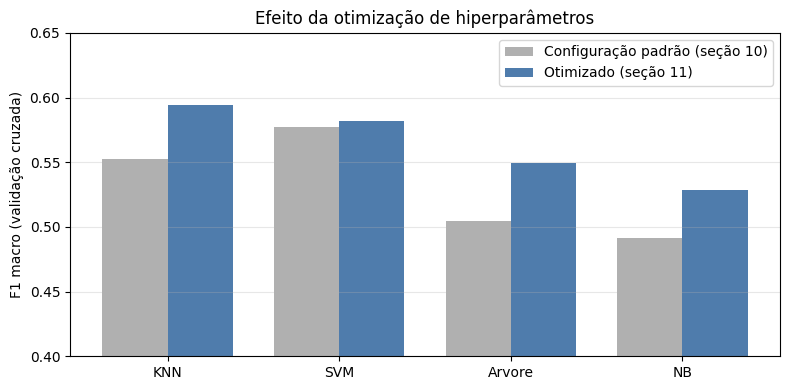

In [20]:
# Gráfico: F1 macro antes e depois da otimização
posicoes = np.arange(len(tabela_otimizacao))
largura = 0.38

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(posicoes - largura / 2, tabela_otimizacao["f1_macro_padrao"], largura,
       label="Configuração padrão (seção 10)", color="#b0b0b0")
ax.bar(posicoes + largura / 2, tabela_otimizacao["f1_macro_otimizado"], largura,
       label="Otimizado (seção 11)", color="#4f7cac")
ax.set_xticks(posicoes)
ax.set_xticklabels(tabela_otimizacao.index)
ax.set_ylabel("F1 macro (validação cruzada)")
ax.set_ylim(0.4, 0.65)
ax.set_title("Efeito da otimização de hiperparâmetros")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Análise da otimização.**

- Todos os algoritmos melhoraram em relação à configuração padrão.
- A Árvore teve o maior ganho, de 0,50 para 0,55 de F1 macro, ao limitar a profundidade a 5 níveis. Sem limite, ela cria regras específicas demais para os vinhos de treino, o que caracteriza *overfitting*. A poda faz a árvore generalizar melhor, como descrito na disciplina.
- O KNN passou o SVM e ficou com o melhor resultado, com F1 macro de 0,595 e acurácia de 61%, usando 21 vizinhos, distância manhattan, votos com peso pela distância e dados padronizados.
- O SVM melhorou pouco, de 0,577 para 0,582, pois a configuração padrão dele já era boa. O kernel `rbf` superou o linear, o que indica que a fronteira entre as classes não é um hiperplano.
- KNN e SVM estão muito próximos. A diferença entre eles, cerca de 0,01, é menor que o desvio padrão das rodadas, cerca de 0,03. Na validação cruzada, os dois são praticamente equivalentes.

Seguindo o critério definido na seção 9, maior F1 macro médio na validação cruzada, o modelo escolhido é o KNN otimizado. A confirmação final é feita na seção 12, com o conjunto de teste, que o modelo nunca viu.

In [21]:
# Escolhe o algoritmo com o maior F1 macro na validação cruzada
nome_escolhido = tabela_otimizacao["f1_macro_otimizado"].idxmax()

# best_estimator_: o pipeline com os melhores hiperparâmetros, já retreinado pelo
# GridSearchCV com todo o conjunto de treino
modelo_escolhido = buscas[nome_escolhido].best_estimator_

print("Algoritmo escolhido:", nome_escolhido)
modelo_escolhido

Algoritmo escolhido: KNN


Pipeline(steps=[('transformacao', StandardScaler()),
                ('modelo',
                 KNeighborsClassifier(metric='manhattan', n_neighbors=21,
                                      weights='distance'))])

## 12. Avaliação Final no Conjunto de Teste

Até aqui, todos os resultados vieram da validação cruzada, que usa apenas o conjunto de treino. O conjunto de teste, separado na seção 8, foi guardado para este momento, pois simula vinhos novos, que o modelo nunca viu.

O teste é usado uma única vez, com o modelo já escolhido na seção 11. Se o teste fosse usado para novos ajustes, ele deixaria de ser uma avaliação honesta, porque o modelo passaria a ser escolhido com base na própria prova.

O modelo é avaliado de três formas:
- **Acurácia e F1 macro no teste**, comparados com os valores da validação cruzada. Valores parecidos indicam que o modelo generaliza bem e não decorou o treino.
- **Relatório por classe**, com precisão, recall e F1 de baixa, média e alta.
- **Matriz de confusão**, que mostra, para cada classe real, quantos vinhos o modelo colocou em cada classe prevista. Ela indica quais confusões o modelo comete.

In [22]:
# Previsões do modelo escolhido para os vinhos do conjunto de teste
y_previsto = modelo_escolhido.predict(X_teste)

acuracia_teste = accuracy_score(y_teste, y_previsto)
f1_macro_teste = f1_score(y_teste, y_previsto, average="macro", zero_division=0)

# Comparação: validação cruzada (seção 11) x conjunto de teste
comparacao_teste = pd.DataFrame({
    "validação cruzada (treino)": [
        tabela_otimizacao.loc[nome_escolhido, "acuracia_otimizada"],
        tabela_otimizacao.loc[nome_escolhido, "f1_macro_otimizado"],
    ],
    "teste": [acuracia_teste, f1_macro_teste],
}, index=["acurácia", "F1 macro"])

comparacao_teste.round(3)

,validação cruzada (treino),teste
acurácia,0.609,0.608
F1 macro,0.595,0.586


In [23]:
# Precisão, recall e F1 de cada classe no conjunto de teste
print(classification_report(
    y_teste, y_previsto, labels=ORDEM_CLASSES, digits=3, zero_division=0,
))

              precision    recall  f1-score   support

       baixa      0.678     0.637     0.657       397
       media      0.567     0.665     0.612       465
        alta      0.582     0.421     0.489       202

    accuracy                          0.608      1064
   macro avg      0.609     0.574     0.586      1064
weighted avg      0.611     0.608     0.605      1064



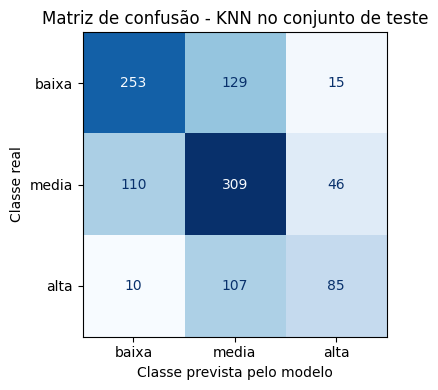

In [24]:
# Matriz de confusão: linhas = classe real, colunas = classe prevista
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_previsto, labels=ORDEM_CLASSES, cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title(f"Matriz de confusão - {nome_escolhido} no conjunto de teste")
ax.set_xlabel("Classe prevista pelo modelo")
ax.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

**Análise da avaliação no teste.**

- O modelo generaliza bem. No teste, a acurácia foi de 60,8% e o F1 macro de 0,586, praticamente iguais aos da validação cruzada, 60,9% e 0,595. A diferença é menor que a variação entre as rodadas da validação cruzada, o que confirma que a escolha feita apenas com o treino vale para vinhos novos.
- O modelo supera com folga a linha de base, que tinha 43,7% de acurácia e F1 macro de 0,20.
- As classes baixa e média são reconhecidas razoavelmente, com recall de 64% e 66%.
- A classe alta é a mais difícil, e o modelo encontra só 42% dos vinhos de alta qualidade. Pela matriz de confusão, a maior parte dos vinhos alta classificados errado, 107 de 202, foi prevista como média. Isso é coerente com dois fatos: Alta é a classe mais rara, e média fica entre as outras duas.
- Os erros acontecem quase sempre entre classes vizinhas. Confundir baixa com alta, o erro mais grave, é raro: 15 vinhos baixa foram previstos como alta e 10 vinhos alta foram previstos como baixa, em um total de 1.064. Quando o modelo erra, normalmente erra por um degrau.

O desempenho é moderado, mas estável. Isso é esperado, porque a nota vem de degustadores e vinhos com química parecida podem receber notas diferentes. Esses pontos são retomados na análise final, na seção 15.

## 13. Exportação do Modelo

O modelo treinado existe apenas na memória do notebook e é perdido quando o Colab fecha. Para que a aplicação *full stack* possa usá-lo, ele precisa ser salvo em um arquivo. A biblioteca `pickle`, vista na disciplina, transforma o objeto Python em uma sequência de bytes e grava esse conteúdo em um arquivo `.pkl`. Depois, o *back-end* lê o arquivo e recria o modelo, pronto para fazer previsões.

Decisões desta etapa:

- **O *pipeline* inteiro é salvo, e não só o KNN.** O *pipeline* guarda a padronização, com a média e o desvio padrão aprendidos no treino, junto com o modelo. Assim, a aplicação envia as medidas originais do vinho e o próprio *pipeline* aplica a mesma padronização do treino. Se apenas o KNN fosse salvo, a aplicação teria que repetir a padronização por conta própria, com risco de erro.
- **O modelo exportado é o treinado apenas com o conjunto de treino**, o mesmo avaliado na seção 12. Assim, o teste automatizado da aplicação, feito com PyTest, pode avaliá-lo em vinhos que ele nunca viu.
- **O conjunto de teste também é salvo em CSV**, com as entradas e a classe correta de cada vinho. Esse arquivo é usado pelo PyTest para verificar se o modelo atende aos limites mínimos de desempenho. Se o modelo for trocado no futuro, o mesmo teste impede a implantação de um modelo pior.
- **É calculado o hash SHA-256 do arquivo do modelo.** Qualquer alteração no arquivo, por menor que seja, muda o hash. Ele é usado pela aplicação para conferir a integridade do modelo antes de carregá-lo, conforme o mecanismo de integridade visto em Desenvolvimento de Software Seguro. Isso é importante porque carregar um `.pkl` executa código, e um arquivo adulterado poderia ser perigoso.
- **Os arquivos são salvos na pasta `exportacao/` do Colab.** Depois da execução, eles são baixados pelo painel de arquivos e enviados ao repositório: O modelo para `api/MachineLearning/pipelines/` e o CSV para `api/MachineLearning/data/`.

Atenção: O arquivo `.pkl` depende da versão do *scikit-learn* usada para criá-lo, exibida na seção 2. A aplicação precisa usar a mesma versão.

In [25]:
PASTA_EXPORTACAO = Path("exportacao")
PASTA_EXPORTACAO.mkdir(exist_ok=True)

ARQUIVO_MODELO = PASTA_EXPORTACAO / "modelo_vinhos.pkl"
ARQUIVO_TESTE = PASTA_EXPORTACAO / "vinhos_teste.csv"

# Salva o pipeline completo (padronização + KNN) em formato binário ("wb")
with open(ARQUIVO_MODELO, "wb") as arquivo:
    pickle.dump(modelo_escolhido, arquivo)

# Salva o conjunto de teste: os 12 atributos de entrada e a classe correta
conjunto_teste = X_teste.copy()
conjunto_teste["classe"] = y_teste
conjunto_teste.to_csv(ARQUIVO_TESTE, index=False)

print(f"Modelo salvo em: {ARQUIVO_MODELO} ({ARQUIVO_MODELO.stat().st_size / 1024:.0f} KB)")
print(f"Conjunto de teste salvo em: {ARQUIVO_TESTE} ({len(conjunto_teste)} vinhos)")

Modelo salvo em: exportacao/modelo_vinhos.pkl (523 KB)
Conjunto de teste salvo em: exportacao/vinhos_teste.csv (1064 vinhos)


In [26]:
# Hash SHA-256 do arquivo do modelo, usado para conferir a integridade
hash_modelo = hashlib.sha256(ARQUIVO_MODELO.read_bytes()).hexdigest()
print("SHA-256 do modelo:", hash_modelo)

SHA-256 do modelo: 1496c6343d246b775b21e4ff36702add864bfa156b8fa1e604216191e3d8840b


### Conferência do Arquivo Salvo

Antes de levar o arquivo para a aplicação, é verificado se ele foi salvo corretamente. O modelo é carregado do arquivo, da mesma forma que o *back-end* fará, e suas previsões no conjunto de teste lido do CSV são comparadas com as do modelo original.

In [27]:
# Carrega o modelo do arquivo em formato binário ("rb"), como a aplicação fará
with open(ARQUIVO_MODELO, "rb") as arquivo:
    modelo_carregado = pickle.load(arquivo)

# Lê o conjunto de teste do CSV salvo
teste_lido = pd.read_csv(ARQUIVO_TESTE)
X_teste_lido = teste_lido[ATRIBUTOS]
y_teste_lido = teste_lido["classe"]

previsoes_iguais = (modelo_carregado.predict(X_teste_lido) == y_previsto).all()
f1_carregado = f1_score(y_teste_lido, modelo_carregado.predict(X_teste_lido),
                        average="macro", zero_division=0)

print("Previsões idênticas às do modelo original:", previsoes_iguais)
print(f"F1 macro do modelo carregado no teste: {f1_carregado:.3f}")

Previsões idênticas às do modelo original: True
F1 macro do modelo carregado no teste: 0.586


**Resultado da exportação:** O modelo carregado do arquivo faz as mesmas previsões que o original e mantém o mesmo F1 macro no teste, 0,586. Os dois arquivos estão prontos para a aplicação: O `modelo_vinhos.pkl`, carregado pelo *back-end*, e o `vinhos_teste.csv`, usado pelo PyTest para conferir o desempenho do modelo.

## 14. Simulação com Vinhos Novos

Até aqui, todos os vinhos usados tinham a classe conhecida. Na aplicação, os vinhos chegam sem classe: o usuário informa as medidas químicas e recebe a qualidade esperada.

Para simular esse uso, foram criados quatro vinhos fictícios, e a previsão é feita pelo modelo carregado do arquivo na seção 13, como o *back-end* fará. Os valores foram escolhidos dentro das faixas observadas na seção 4, para representar perfis diferentes:

| Vinho | Perfil |
|---|---|
| 1 | Tinto com acidez volátil alta e pouco álcool |
| 2 | Tinto com medidas intermediárias |
| 3 | Branco com medidas típicas |
| 4 | Branco com teor alcoólico alto e poucos cloretos |

Além da classe prevista, é exibida a probabilidade de cada classe. No KNN, ela vem do voto dos 21 vizinhos mais parecidos, com mais peso para os mais próximos. Uma probabilidade alta indica que quase todos os vizinhos concordam. Probabilidades parecidas entre duas classes indicam um vinho de fronteira, em que o modelo está menos seguro.

In [28]:
# Vinhos fictícios: as mesmas 12 entradas usadas no treino, na mesma ordem
vinhos_novos = pd.DataFrame([
    [7.8, 0.70, 0.05, 2.0, 0.090, 12.0, 45.0, 0.9975, 3.40, 0.55, 9.3, 0],
    [7.2, 0.30, 0.35, 2.2, 0.065, 15.0, 40.0, 0.9960, 3.30, 0.70, 11.0, 0],
    [6.8, 0.25, 0.32, 6.0, 0.045, 35.0, 135.0, 0.9940, 3.20, 0.48, 10.5, 1],
    [6.5, 0.25, 0.35, 2.0, 0.030, 35.0, 110.0, 0.9905, 3.25, 0.50, 12.8, 1],
], columns=ATRIBUTOS, index=["vinho 1", "vinho 2", "vinho 3", "vinho 4"])

vinhos_novos

,acidez_fixa,acidez_volatil,acido_citrico,acucar_residual,cloretos,dioxido_enxofre_livre,dioxido_enxofre_total,densidade,ph,sulfatos,alcool,tipo_branco
vinho 1,7.8,0.70,0.05,2.0,0.090,12.0,45.0,0.9975,3.40,0.55,9.3,0
vinho 2,7.2,0.30,0.35,2.2,0.065,15.0,40.0,0.9960,3.30,0.70,11.0,0
vinho 3,6.8,0.25,0.32,6.0,0.045,35.0,135.0,0.9940,3.20,0.48,10.5,1
vinho 4,6.5,0.25,0.35,2.0,0.030,35.0,110.0,0.9905,3.25,0.50,12.8,1


In [29]:
# Previsão com o modelo carregado do arquivo, como a aplicação fará
classes_previstas = modelo_carregado.predict(vinhos_novos)

# Probabilidade de cada classe, na ordem baixa, média e alta
probabilidades = pd.DataFrame(
    modelo_carregado.predict_proba(vinhos_novos),
    columns=modelo_carregado.classes_,
    index=vinhos_novos.index,
)[ORDEM_CLASSES]

resultado_simulacao = (probabilidades * 100).round(0).astype(int).astype(str) + "%"
resultado_simulacao.insert(0, "classe prevista", classes_previstas)
resultado_simulacao

,classe prevista,baixa,media,alta
vinho 1,baixa,83%,13%,4%
vinho 2,media,23%,41%,36%
vinho 3,media,38%,58%,4%
vinho 4,alta,0%,45%,55%


**Resultado da simulação:** O modelo funciona com dados novos, sem classe conhecida, e as previsões são coerentes com o comportamento dos dados:

- O vinho 1, com acidez volátil alta e pouco álcool, foi classificado como baixa com bastante segurança. Acidez volátil alta está ligada ao gosto de vinagre, e pouco álcool é comum nos vinhos com notas baixas.
- O vinho 4, com muito álcool, foi classificado como alta, com média logo atrás. O teor alcoólico é a medida que mais acompanha as notas altas neste dataset, e a proximidade com média repete o comportamento visto na seção 12, em que alta e média são as classes que o modelo mais confunde.
- O vinho 3, um branco típico, foi classificado como média, a classe mais comum.
- O vinho 2 também foi classificado como média, mas com probabilidades bem divididas entre as três classes. É um vinho de fronteira, região em que o modelo mais erra.

Na aplicação, além da classe, as probabilidades também serão exibidas, pois indicam ao usuário o grau de segurança da resposta.

## 15. Análise dos Resultados e Conclusão

### Principais Achados

- **A avaliação dos especialistas pode ser prevista a partir das medidas químicas, com desempenho moderado.** O modelo final, um KNN, acerta 60,8% dos vinhos no teste, com F1 macro de 0,586. A linha de base, que sempre responde a classe mais comum, acerta 43,7% e tem F1 macro de 0,20.
- **Os resultados são consistentes.** O desempenho no teste, na seção 12, ficou praticamente igual ao da validação cruzada, na seção 11, o que indica que o modelo generaliza para vinhos que nunca viu. Esse resultado é coerente com os cuidados tomados contra vazamento de dados: Remoção de duplicatas antes do *holdout*, transformações dentro dos *pipelines* e uso único do conjunto de teste.
- **A escala dos dados importa muito para alguns algoritmos.** Sem padronização ou normalização, o F1 macro do SVM caiu para 0,33 e o do KNN para 0,44. Árvore e Naive Bayes praticamente não mudaram, como a teoria prevê.
- **A otimização de hiperparâmetros melhorou todos os algoritmos.** O maior ganho foi da Árvore, ao limitar a profundidade, uma forma de poda contra o *overfitting*.
- **A classe alta é a mais difícil.** O modelo encontra só 42% desses vinhos, e a maioria dos erros vira média. Por outro lado, os erros acontecem quase sempre entre classes vizinhas, e confundir baixa com alta é raro.

### Escolha do KNN

O critério de escolha foi definido na seção 9, antes de os resultados serem conhecidos: O algoritmo com o maior F1 macro médio na validação cruzada. O KNN otimizado ficou com 0,595 e o SVM com 0,582. A diferença entre os dois, cerca de 0,01, é menor que a variação entre as rodadas da validação cruzada, cerca de 0,03. Os dois estão tecnicamente empatados, e o critério definido antes serviu para desempatar de forma objetiva. A escolha não foi revista depois do teste, para que a avaliação final continuasse honesta.

O KNN tem a vantagem de ser fácil de explicar, pois a previsão se baseia nas notas dos vinhos mais parecidos. A principal desvantagem é guardar todos os vinhos de treino dentro do modelo. O arquivo exportado tem 523 KB, e cada previsão compara o vinho novo com os 4.256 vinhos de treino. Com milhões de registros, o modelo ficaria lento e pesado, mas neste problema isso não é um obstáculo.

### Pontos de Atenção e Limitações

- **A nota é subjetiva.** Ela vem de degustadores, e vinhos com química parecida podem receber notas diferentes. Isso limita o quanto qualquer modelo pode acertar usando apenas medidas químicas.
- **As classes são desbalanceadas**, e alta é a mais rara, com 19% dos vinhos. Por isso o F1 macro foi a métrica principal e a estratificação foi aplicada em todas as divisões, mas a classe rara continua sendo a mais difícil.
- **Os dados são de uma só região e época**, vinhos da denominação Vinho Verde, do norte de Portugal. O modelo não deve ser usado para outros tipos de vinho sem novos dados. Se os padrões mudarem com o tempo, o chamado *concept drift*, o modelo precisará ser retreinado.
- **Foram usados apenas os quatro algoritmos pedidos**, KNN, Árvore, Naive Bayes e SVM, e as medidas químicas originais, sem criação de novos atributos.

### Melhorias Futuras

- Testar algoritmos mais avançados, como os *ensembles*, por exemplo o *Random Forest*, citados na disciplina.
- Tratar o desbalanceamento de forma específica, por exemplo dando mais peso à classe alta no treino.
- Testar seleção de atributos e criação de novos atributos a partir dos existentes.
- Coletar mais exemplos de vinhos de qualidade alta.

### Conclusão

O notebook percorreu todas as etapas pedidas: Carga dos dados por URL, limpeza, separação em treino e teste, transformação dos dados com padronização e normalização, comparação dos quatro algoritmos com validação cruzada e *pipelines*, otimização de hiperparâmetros, avaliação final no teste e exportação do modelo. O resultado é um modelo estável, que supera com folga a linha de base, embora com desempenho moderado por causa da natureza subjetiva do problema.

O modelo exportado, `modelo_vinhos.pkl`, será carregado pela aplicação *full stack*, e o conjunto de teste exportado, `vinhos_teste.csv`, será usado pelo teste automatizado com PyTest, que impede a implantação de um modelo abaixo dos limites mínimos de desempenho.

## 16. Reflexão sobre Segurança e Proteção de Dados

Esta seção apresenta como as boas práticas da disciplina Desenvolvimento de Software Seguro se aplicam a este problema e à aplicação que usa o modelo.

### Dados Pessoais e Anonimização

O dataset *Wine Quality* não contém dados pessoais. Cada linha é um vinho, com medidas de laboratório e uma nota, sem nome de produtor, de degustador, de cliente ou qualquer outro identificador. Por isso, neste projeto, não foi necessário aplicar técnicas de anonimização.

Se o problema passasse a usar dados de pessoas, como na ideia inicial deste trabalho, de prever se uma pessoa vai gostar de um livro a partir da idade, do gênero e das preferências dela, ou como em um cadastro de clientes de uma vinícola, a LGPD passaria a valer. Nesse caso, as técnicas vistas na disciplina seriam necessárias antes de compartilhar os dados ou usá-los no treino:

- **Supressão:** Remover identificadores diretos, como nome, CPF e e-mail, que não ajudam o modelo.
- **Generalização:** Trocar valores exatos por faixas, como a idade 34 pela faixa de 30 a 39 anos, ou o endereço completo apenas pela cidade.
- **Pseudoanonimização:** Substituir identificadores por códigos e guardar a tabela de correspondência separada e protegida.
- **Avaliação de identificabilidade:** Feita antes e depois da aplicação das técnicas, já que combinações de atributos como idade, cidade e gênero podem identificar alguém mesmo sem o nome.

Há também um equilíbrio a buscar, pois quanto mais os dados são anonimizados, menos úteis eles ficam. Trocar a idade exata por faixas, por exemplo, protege a pessoa, mas tira do modelo um detalhe que poderia ajudar na previsão. O ideal é anonimizar o máximo possível sem perder a utilidade dos dados para a finalidade do modelo.

Existe um ponto específico do modelo escolhido: O KNN guarda todos os exemplos de treino dentro do arquivo `.pkl`. Se os dados fossem pessoais, quem obtivesse o arquivo do modelo teria acesso aos dados de todas as pessoas do treino. Nesse cenário, o arquivo do modelo teria que ser protegido como uma base de dados pessoais, ou seria preferível um algoritmo que não guarda os exemplos.

### Integridade do Modelo

Carregar um arquivo `.pkl` com `pickle` executa código, e um arquivo adulterado poderia rodar comandos maliciosos no servidor. Por isso, na seção 13, foi calculado o hash SHA-256 do modelo. A aplicação recalcula o hash do arquivo antes de carregá-lo e só o usa se o valor for igual ao esperado. Esse é o mecanismo de integridade visto na disciplina. Além disso, a aplicação só deve carregar modelos gerados por este processo, nunca arquivos de origem desconhecida.

### Cuidados na Aplicação

- **Validação das entradas:** O *back-end* aceita apenas números dentro de faixas plausíveis, como pH entre 2 e 5 e álcool entre 5% e 20%, e o tipo do vinho apenas como 0 ou 1. Qualquer outro valor é recusado com uma mensagem clara. Isso evita erros e o uso de entradas inesperadas para atacar o sistema.
- **Registros sem os dados enviados:** Os *logs* registram que houve uma previsão e se ela deu certo, sem guardar os valores enviados pelo usuário. Aqui os dados não são sensíveis, mas essa é a boa prática de *privacy by design*, de guardar apenas o necessário.
- **Sem banco de dados:** A aplicação não armazena as consultas, o que reduz o que poderia vazar.
- **Componentes de terceiros:** As versões das bibliotecas ficam fixadas no `requirements.txt`, o que permite saber quais versões estão em uso e verificar vulnerabilidades conhecidas (CVE) nelas.
- **Comunicação segura:** Em um ambiente real, a aplicação deveria ser publicada com HTTPS, para que os dados trafeguem cifrados entre o navegador e o servidor.
- **Controle de qualidade do modelo:** O teste automatizado com PyTest impede que um modelo pior, ou um arquivo errado, seja colocado em uso sem que ninguém perceba.